# Tutorial 2 - Enrich a pre-created PyPSA model with new elements

## 1. Re-load the model of the NL created in Tutorial 1

In [1]:
import pypsa
import plotly.express as px
import pandas as pd

In [2]:
n = pypsa.Network("output_data/reference_2019_model.xlsx")

/home/fl/GitHub/electricity-market-scenarios-in-PyPSA/.pixi/envs/default/lib/python3.15/site-packages/pypsa/network/io.py:2079: FutureWarning: pandas infers the `str` dtype for string data since its version 3.0. PyPSA still converts it back to numpy object dtype on import, but will keep it from PyPSA 2.0 on. Set `pypsa.options.api.legacy_string_dtype` explicitly to suppress this warning.
  new_static = _coerce_string_dtypes(new_static)
INFO:pypsa.network.io:Imported network 'Unnamed Network' has buses, carriers, generators, loads, sub_networks


In [3]:
n

PyPSA Network 'Unnamed Network'
-------------------------------
Components:
 - Bus: 1
 - Carrier: 9
 - Generator: 8
 - Load: 1
 - SubNetwork: 1
Snapshots: 8760

In [4]:
# And let's reload the techno-economic parameters, since the battery will need them
technoecon_params = pd.read_csv('input_data/technoecon_params.csv', index_col=0)

In [5]:
technoecon_params

,fuel,VOM,efficiency,FOM,CO2 intensity,lifetime,investment,installed_capacity
ccgt,11.6278,5.8775,0.5600,3.3295,0.1980,25.0,1175506.7,17470.5
solar,0.0000,0.0134,0.0000,1.5780,0.0000,35.0,1018204.4,7366.1
wind-onshore,0.0000,2.0037,0.0000,1.2514,0.0000,27.0,1494463.1,5505.8
wind-offshore,0.0000,0.0267,0.0000,2.5093,0.0000,27.0,2505378.1,7138.0
nuclear,7.4536,4.4590,0.3260,1.2700,0.0000,40.0,10805703.8,515.0
battery,0.0000,0.0000,0.9500,0.2000,0.0000,15.0,1601785.4,263.4
biomass,9.3506,2.8138,0.2994,3.6081,NaN,25.0,4516713.3,1573.2
coal,7.8202,4.1005,0.3560,1.3100,0.3361,40.0,4812024.4,6007.0


## 2. Introduce a new technology: battery storage

In [6]:
n.add("Carrier", name="battery", color='cyan')

n.add(
    "StorageUnit",
    "battery",
    bus="electricity",
    carrier="battery",
    max_hours=4,
    capital_cost=technoecon_params.loc['battery','investment'],
    efficiency_store=technoecon_params.loc['battery','efficiency'],
    efficiency_dispatch=technoecon_params.loc['battery','efficiency'],
    cyclic_state_of_charge=True, # Ensures that energy is the same at the start and end of the problem, avoiding 'for-free' initial stored energy
    p_nom=technoecon_params.loc['battery','installed_capacity']
)


In [7]:
n.optimize()

/tmp/ipykernel_125768/1261279110.py:1: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize()
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|████████████| 4/4 [00:00<00:00, 193.13it/s]
INFO:linopy.io: Writing time: 0.18s


Running HiGHS 1.15.1 (git hash: n/a): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-g0yrz4we has 245276 rows; 96360 cols; 385432 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 1e+00]
  Cost    [1e-02, 2e+02]
  Bound   [0e+00, 0e+00]
  RHS     [6e-01, 2e+04]
Presolving model
52556 rows, 74754 cols, 171106 nonzeros 0s
28922 rows, 53417 cols, 90269 nonzeros 0s
Dependent equations search running on 11404 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
28922 rows, 53417 cols, 90269 nonzeros 0s
Presolve reductions: rows 28922(-216354); columns 53417(-42943); nonzeros 90269(-295163) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.6s
      12637     1.9657607554e+09 Pr: 0(0); Du: 0(5.32907e-15) 0.9s

Performed posts

INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 96360 primals, 350400 duals
Objective: 1.97e+09
Solver: highs
Runtime: 1.02s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Generator-p-ramp_limit_up, Generator-p-ramp_limit_down, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance were not assigned to the network.


('ok', 'optimal')

### 2.1 Inspect the results with the new technology

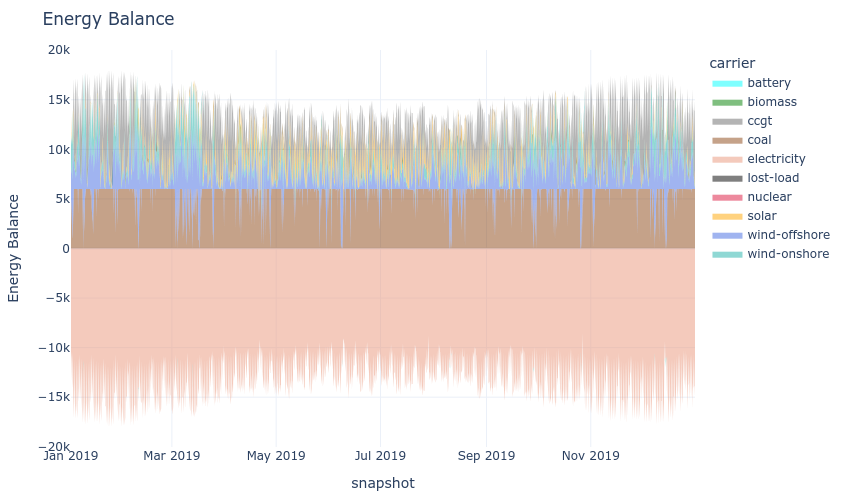

In [8]:
# Energy balance
n.statistics.energy_balance.iplot.area()

**Note**: Nothing really changes, and that shouldn't be a surprise. We used the installed battery capacity from 2019, which was not much! The same goes for renewables, which were not yet large enough in 2019 to have excess generation (also known as 'curtailment') that batteries could help with. So, let's see what things could look like in a more renewables-dominated case.

### 2.2 Make the results more interesting: more renewables and more battery

In [9]:
n.generators.loc['wind-offshore','p_nom'] = 2*n.generators.loc['wind-offshore','p_nom']
n.generators.loc['solar','p_nom'] = 1.5*n.generators.loc['solar','p_nom']
n.storage_units.loc['battery','p_nom'] = 100*n.storage_units.loc['battery','p_nom']

/tmp/ipykernel_125768/119454345.py:1: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize()
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|████████████| 4/4 [00:00<00:00, 117.14it/s]
INFO:linopy.io: Writing time: 0.25s


Running HiGHS 1.15.1 (git hash: n/a): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-b_ln8q29 has 245276 rows; 96360 cols; 385432 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 1e+00]
  Cost    [1e-02, 2e+02]
  Bound   [0e+00, 0e+00]
  RHS     [6e-01, 1e+05]
Presolving model
52556 rows, 91998 cols, 188350 nonzeros 0s
Dependent equations search running on 17520 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.01s (limit = 1000.00s)
35038 rows, 91998 cols, 153314 nonzeros 0s
Presolve reductions: rows 35038(-210238); columns 91998(-4362); nonzeros 153314(-232118) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Pr: 8760(1.13901e+08) 0.8s
      26526     1.3490375868e+09 Pr: 0(0); Du: 0(1.9984e-14) 1.7s

Performed postsolve
Solving the original LP f

INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 96360 primals, 350400 duals
Objective: 1.35e+09
Solver: highs
Runtime: 1.92s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Generator-p-ramp_limit_up, Generator-p-ramp_limit_down, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance were not assigned to the network.


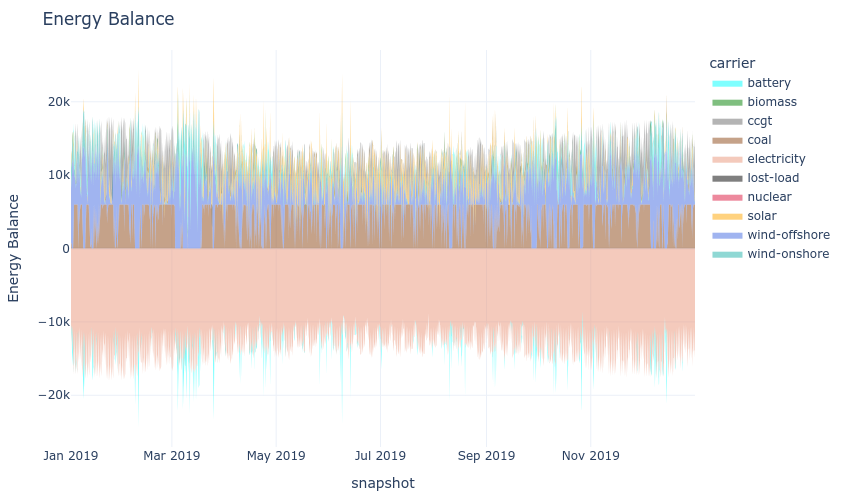

In [10]:
n.optimize()
n.statistics.energy_balance.iplot.area()

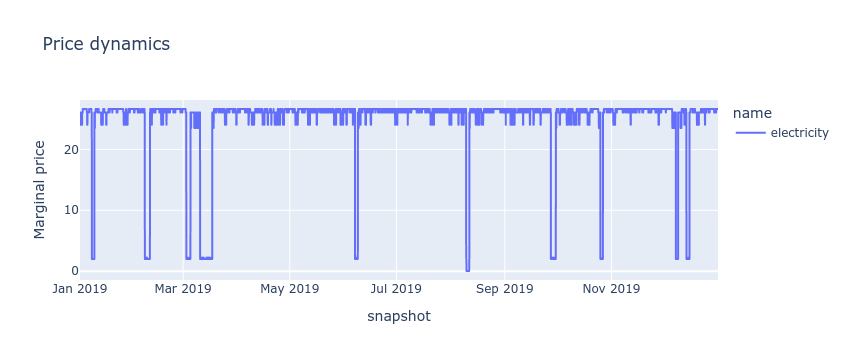

In [11]:
# Prices over time
df = n.buses_t.marginal_price.loc['2019-01-01':'2019-12-31']

fig = px.line(
    df,
    title="Price dynamics",
    labels={
        "index": "Time",
        "value": "Marginal price",
        "variable": "Bus"
    }
)
fig.show()

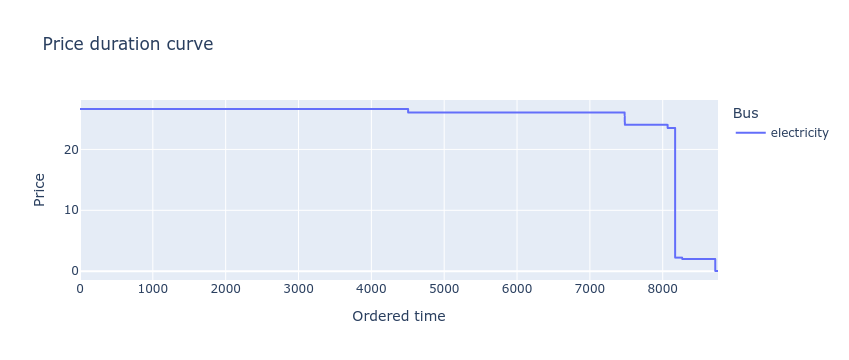

In [12]:
pdc = n.buses_t.marginal_price['electricity'].loc['2019-01-01':'2019-12-31'].sort_values(ascending=False).reset_index(drop=True)

fig = px.line(
    pdc,
    title="Price duration curve",
    labels={
        "index": "Ordered time",
        "value": "Price",
        "variable": "Bus"
    }
)
fig.show()

In [13]:
# Simplified (i.e., no discount rate) cost recovery example
total_investment = (technoecon_params['investment']*n.generators.p_nom).dropna() # As long as tech names are the same
yearly_revenues = n.statistics.revenue(carrier=total_investment.index).droplevel("component")
payback_time = total_investment/yearly_revenues
payback_time

biomass                NaN
ccgt             58.004011
coal             29.271814
nuclear                NaN
solar            37.016868
wind-offshore    40.470692
wind-onshore     33.379795
dtype: float64

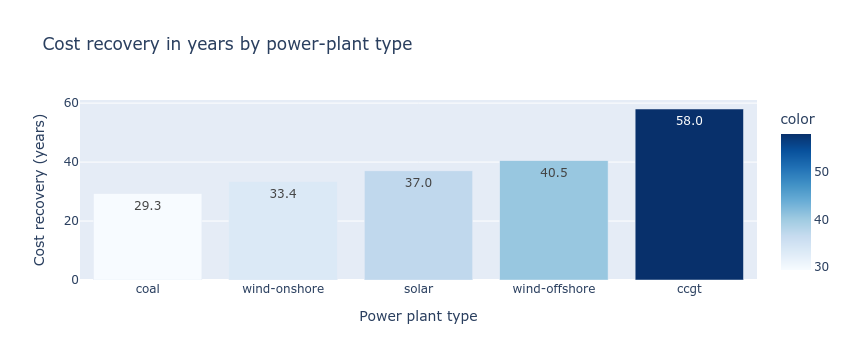

In [14]:
# Let's make it visual
data = payback_time.dropna().sort_values()
fig = px.bar(
    data,
    x=data.index,
    y=data.values,
    title="Cost recovery in years by power-plant type",
    labels={
        "x": "Power plant type",
        "y": "Cost recovery (years)"
    },
    text_auto=".1f",
    color=data.values.round(2),
    color_continuous_scale="Blues",
)
fig.show()

## 3. A different scenario: introduce a carbon tax 
Let's start again from the initial model, without batteries or expanded renewables

In [16]:
n = pypsa.Network("output_data/reference_2019_model.xlsx")

INFO:pypsa.network.io:Imported network 'Unnamed Network' has buses, carriers, generators, loads, sub_networks


### 3.1 Define the tax and convert to marginal extra-cost per generator

In [17]:
carbon_tax = 80 # Eur per tonnes of CO2

In [18]:
co2_in_fuels = n.carriers['co2_emissions'].loc[n.generators.index]
co2_in_fuels

name
solar            0.0000
wind-onshore     0.0000
wind-offshore    0.0000
ccgt             0.1980
coal             0.3361
biomass          0.0000
nuclear          0.0000
lost-load        0.0000
Name: co2_emissions, dtype: float64

In [19]:
carbon_tax_per_mwh = carbon_tax*co2_in_fuels/n.generators['efficiency']
carbon_tax_per_mwh

name
solar             0.000000
wind-onshore      0.000000
wind-offshore     0.000000
ccgt             28.285714
coal             75.528090
biomass           0.000000
nuclear           0.000000
lost-load         0.000000
dtype: float64

In [20]:
n.generators.marginal_cost # Before the tax

name
solar              0.013400
wind-onshore       2.003700
wind-offshore      0.026700
ccgt              26.641429
coal              26.067354
biomass           34.044929
nuclear           27.322804
lost-load        150.000000
Name: marginal_cost, dtype: float64

In [21]:
n.generators.marginal_cost = n.generators.marginal_cost + carbon_tax_per_mwh
n.generators.marginal_cost # After the tax

name
solar              0.013400
wind-onshore       2.003700
wind-offshore      0.026700
ccgt              54.927143
coal             101.595444
biomass           34.044929
nuclear           27.322804
lost-load        150.000000
Name: marginal_cost, dtype: float64

### 3.2 Re-run the model and see how the merit order and prices change

/tmp/ipykernel_125768/119454345.py:1: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize()
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|████████████| 1/1 [00:00<00:00, 124.19it/s]
INFO:linopy.io: Writing time: 0.09s


Running HiGHS 1.15.1 (git hash: n/a): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-p0jx9q86 has 183956 rows; 70080 cols; 280312 nonzeros
Coefficient ranges:
  Matrix  [1e+00, 1e+00]
  Cost    [1e-02, 2e+02]
  Bound   [0e+00, 0e+00]
  RHS     [6e-01, 2e+04]
Presolving model
43796 rows, 57015 cols, 127087 nonzeros 0s
21319 rows, 34721 cols, 59839 nonzeros 0s
Dependent equations search running on 3801 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
21319 rows, 34721 cols, 59839 nonzeros 0s
Presolve reductions: rows 21319(-162637); columns 34721(-35359); nonzeros 59839(-220473) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.4s
       3842     3.6830196696e+09 Pr: 0(0) 0.5s

Performed postsolve
Solving the orig

INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 70080 primals, 289080 duals
Objective: 3.68e+09
Solver: highs
Runtime: 0.59s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Generator-p-ramp_limit_up, Generator-p-ramp_limit_down were not assigned to the network.


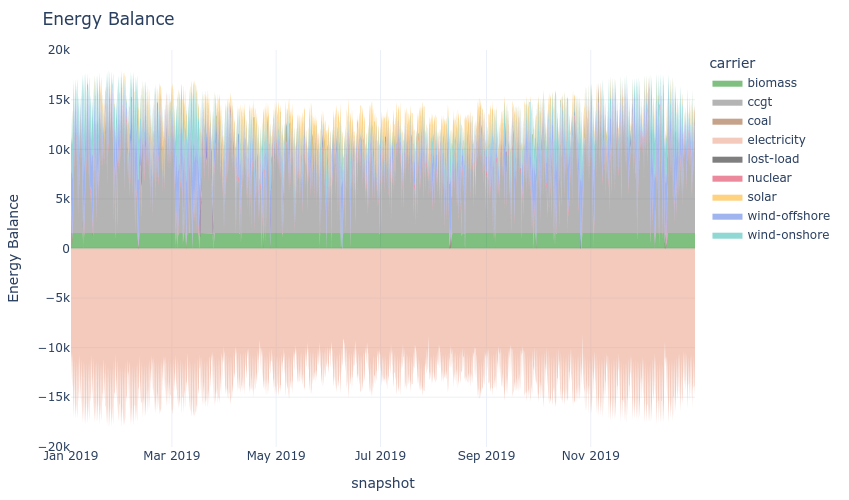

In [22]:
n.optimize()
n.statistics.energy_balance.iplot.area()

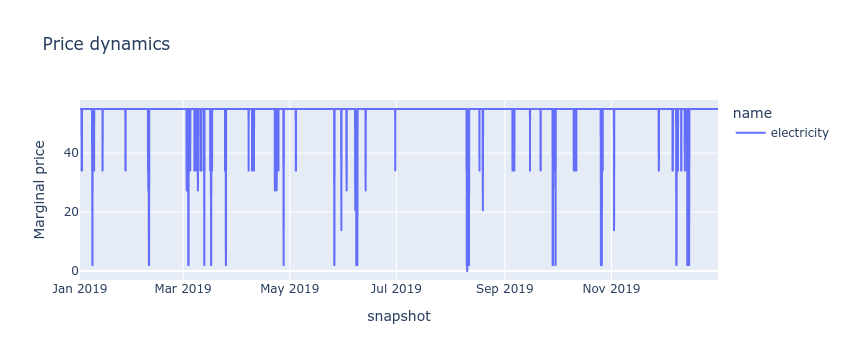

In [23]:
# Prices over time
df = n.buses_t.marginal_price.loc['2019-01-01':'2019-12-31']

fig = px.line(
    df,
    title="Price dynamics",
    labels={
        "index": "Time",
        "value": "Marginal price",
        "variable": "Bus"
    }
)
fig.show()

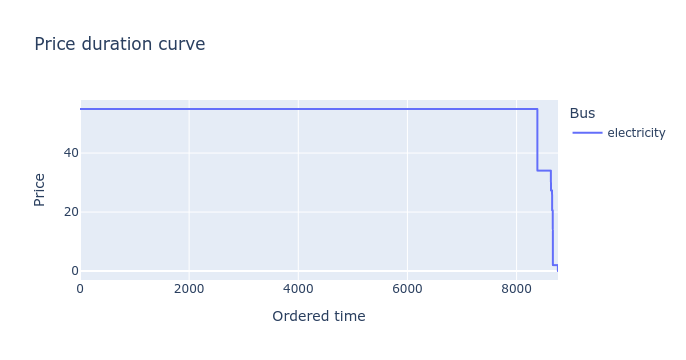

In [24]:
pdc = n.buses_t.marginal_price['electricity'].loc['2019-01-01':'2019-12-31'].sort_values(ascending=False).reset_index(drop=True)

fig = px.line(
    pdc,
    title="Price duration curve",
    labels={
        "index": "Ordered time",
        "value": "Price",
        "variable": "Bus"
    }
)
fig.show()

In [25]:
# Simplified (i.e., no discount rate) cost recovery example
total_investment = (technoecon_params['investment']*n.generators.p_nom).dropna() # As long as tech names are the same
yearly_revenues = n.statistics.revenue(carrier=total_investment.index).droplevel("component")
payback_time = total_investment/yearly_revenues
payback_time

biomass           9.713056
ccgt              6.664298
coal                   NaN
nuclear          23.046917
solar            17.462955
wind-offshore    17.111630
wind-onshore     13.851557
dtype: float64

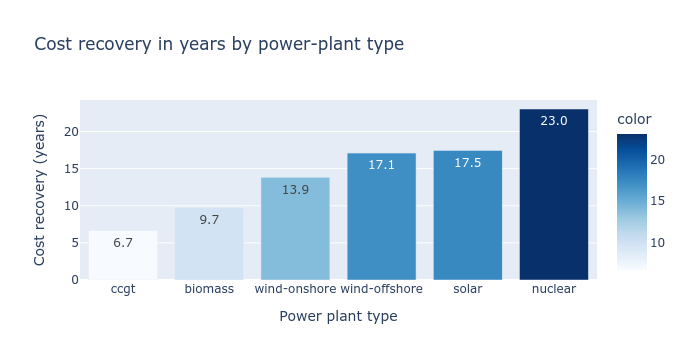

In [26]:
# Let's make it visual
data = payback_time.dropna().sort_values()
fig = px.bar(
    data,
    x=data.index,
    y=data.values,
    title="Cost recovery in years by power-plant type",
    labels={
        "x": "Power plant type",
        "y": "Cost recovery (years)"
    },
    text_auto=".1f",
    color=data.values.round(2),
    color_continuous_scale="Blues",
)
fig.show()

In [27]:
n.statistics.market_value(components='Generator')

carrier
biomass          54.594782
ccgt             54.927143
coal                   NaN
lost-load              NaN
nuclear          54.300022
solar            52.612779
wind-offshore    51.555073
wind-onshore     51.581736
dtype: float64

In [28]:
emissions = (
    n.generators_t.p
    .multiply(n.snapshot_weightings.generators, axis=0)
    .divide(n.generators.efficiency, axis=1)
    .multiply(n.generators.carrier.map(n.carriers.co2_emissions), axis=1)
    .sum()
)
print(emissions)
print(emissions.sum().round(0))

name
solar            0.000000e+00
wind-onshore     0.000000e+00
wind-offshore    0.000000e+00
ccgt             1.983655e+07
coal             0.000000e+00
biomass          0.000000e+00
nuclear          0.000000e+00
lost-load        0.000000e+00
dtype: float64
19836553.0


### 3.3 Export the carbon-tax model, then compare with the original model

In [29]:
n.export_to_excel("output_data/carbontax_2019_model.xlsx")

INFO:pypsa.network.io:Exported network 'Unnamed Network' saved to 'output_data/carbontax_2019_model.xlsx contains: loads, buses, generators, carriers, sub_networks


In [30]:
# Let's reload the original reference model for comparison
n_ref = pypsa.Network("output_data/reference_2019_model.xlsx")

INFO:pypsa.network.io:Imported network 'Unnamed Network' has buses, carriers, generators, loads, sub_networks


In [31]:
pdc_ref = n_ref.buses_t.marginal_price['electricity'].loc['2019-01-01':'2019-12-31'].sort_values(ascending=False).reset_index(drop=True)

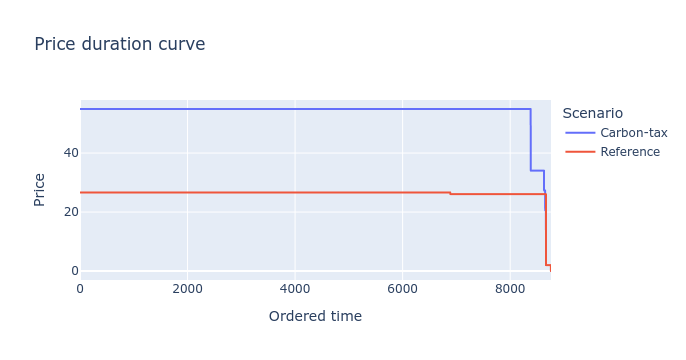

In [32]:
df = pd.concat(
    [pdc.rename("Carbon-tax"), pdc_ref.rename("Reference")],
    axis=1
)

fig = px.line(
    df,
    title="Price duration curve",
    labels={
        "index": "Ordered time",
        "value": "Price",
        "variable": "Scenario"
    }
)
fig.show()

In [33]:
# Now let's retrieve the original model's cost recovery
total_investment_ref = (technoecon_params['investment']*n_ref.generators.p_nom).dropna() 
yearly_revenues_ref = n_ref.statistics.revenue(carrier=total_investment.index).droplevel("component")
payback_time_ref = total_investment_ref/yearly_revenues_ref

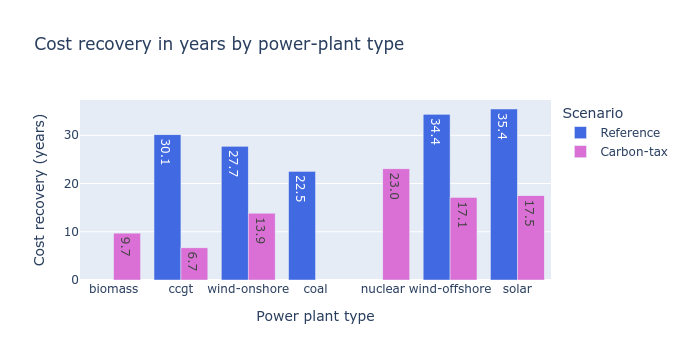

In [34]:
# And plot them next to each other!
# First, we combined them into a single dataframe
combined = pd.concat([payback_time_ref, payback_time], axis=1)

# Then, we sort (for nicer visual effect) by the average payback time across scenarios
combined = combined.loc[
    combined.mean(axis=1).sort_values().index
]
combined.columns = ["Reference", "Carbon-tax"]

# Finally, we plot!
fig = px.bar(
    combined,
    barmode="group",
    title="Cost recovery in years by power-plant type",
    labels={
        "index": "Power plant type",
        "value": "Cost recovery (years)",
        "variable": "Scenario",
    },
    text_auto=".1f",
    color_discrete_sequence=["royalblue", "orchid"],
)

fig.show()